# MODUL 11: PEMBELAJARAN MENDALAM (DEEP LEARNING 1)
### LAPORAN DAN KUMPULAN PRAKTIKUM LENGKAP
**Mata Kuliah:** Kecerdasan Buatan  
**Program Studi:** D-III Manajemen Informatika  
**Dosen Pengampu:** Abidatul Izzah, S.Kom., M.Kom.  

Notebook ini memuat seluruh materi praktikum pada Bab 11:
- **Praktikum 11.1:** Klasifikasi Citra Menggunakan CNN (Mobil vs Motor dengan Evaluasi Lengkap)
- **Praktikum 11.2:** Pemisahan Modul Training & Inference 2 Kelas (Pengujian Citra Baru tes1 & tes2)
- **Praktikum 11.3:** Klasifikasi Citra Multi-Kelas (5 Kelas Makanan Tradisional & Sayuran)
- **Latihan:** Klasifikasi Citra Daun Tanaman (*Plant Leaves Dataset*)
- **Tugas:** Sistem Login Verifikasi Wajah 3 Mahasiswa

In [1]:
# ==========================================================
# SETUP GOOGLE COLAB: GPU & AUTO-DOWNLOAD DATASET
# ==========================================================
import os
import tensorflow as tf

# 1. Cek Ketersediaan GPU (T4 GPU di Google Colab)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'>>> [AKTIF] Akselerasi GPU Terdeteksi: {gpus[0].name}')
    print('>>> Model akan dilatih dengan kecepatan tinggi di GPU!')
else:
    print('>>> [PERINGATAN] GPU belum aktif. Masuk menu: Runtime -> Ubah jenis runtime -> Pilih T4 GPU.')

# 2. Otomatisasi Unduh & Ekstrak Dataset Lengkap
if not os.path.exists('Dataset 1') or not os.path.exists('Dataset 2') or not os.path.exists('Dataset 3'):
    print('\n>>> Mengunduh dataset praktikum dari server CDN...')
    os.system('wget -q https://files.catbox.moe/po8wfa.zip -O dataset_modul11.zip')
    os.system('unzip -q -o dataset_modul11.zip')
    print('>>> [SUKSES] Dataset 1, Dataset 2, dan Dataset 3 berhasil diekstrak dan siap digunakan!')
else:
    print('>>> [INFO] Folder dataset sudah lengkap di direktori kerja.')


>>> [PERINGATAN] GPU belum aktif. Masuk menu: Runtime -> Ubah jenis runtime -> Pilih T4 GPU.
>>> [INFO] Folder dataset sudah lengkap di direktori kerja.


### Langkah 1: Import Library dan Inisialisasi Parameter
Mengimpor library `numpy`, `matplotlib.pyplot`, TensorFlow Keras, dan Scikit-Learn metrics.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix, classification_report
import os

# PARAMETER
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
dataset_path = "Dataset 1/Dataset" if os.path.exists("Dataset 1/Dataset") else "Dataset"

print("Parameter selesai diinisialisasi.")

Parameter selesai diinisialisasi.


### Langkah 2: Pembagian Dataset Training dan Testing (Validasi)
Dataset dibagi menjadi 70% data training dan 30% data validasi menggunakan `ImageDataGenerator(validation_split=0.3)`. Citra dinormalisasi ke rentang [0, 1] melalui `rescale=1./255`.

In [3]:
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.3)

train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    shuffle=True
)

validation_data = datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False
)

total_data = train_data.samples + validation_data.samples
print("====================================")
print("JUMLAH DATA")
print("====================================")
print("Total data :", total_data)
print("Data training :", train_data.samples)
print("Data validasi :", validation_data.samples)
print("Training :", round(train_data.samples/total_data*100, 2), "%")
print("Validasi :", round(validation_data.samples/total_data*100, 2), "%")
print("Class mapping :", train_data.class_indices)

Found 14 images belonging to 2 classes.


Found 6 images belonging to 2 classes.


JUMLAH DATA
Total data : 20
Data training : 14
Data validasi : 6
Training : 70.0 %
Validasi : 30.0 %
Class mapping : {'Mobil': 0, 'Motor': 1}


### Langkah 3: Membangun Arsitektur Model CNN
Arsitektur terdiri dari:
- 3 blok Konvolusi + MaxPooling bertingkat (32, 64, 128 filter)
- Flatten layer
- Dense hidden layer 128 unit (ReLU)
- Dropout 0.5 (mencegah overfitting)
- Dense output 1 unit dengan fungsi aktivasi Sigmoid (Klasifikasi Biner Mobil vs Motor)

In [4]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(224, 224, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 4: Pelatihan Model dan Visualisasi Grafik Akurasi & Loss
Model dilatih selama 20 epoch. Nilai akurasi dan loss pada data training dan validasi divisualisasikan dalam grafik pergerakan per epoch.

Epoch 1/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5714 - loss: 0.6907

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5714 - loss: 0.6907 - val_accuracy: 0.5000 - val_loss: 1.0270


Epoch 2/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step - accuracy: 0.6429 - loss: 0.7548

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 354ms/step - accuracy: 0.6429 - loss: 0.7548 - val_accuracy: 0.5000 - val_loss: 3.4174


... (50 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step - accuracy: 1.0000 - loss: 0.0081 - val_accuracy: 0.8333 - val_loss: 0.5358


Epoch 20/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 1.0000 - loss: 0.0014

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step - accuracy: 1.0000 - loss: 0.0014 - val_accuracy: 0.8333 - val_loss: 0.7346


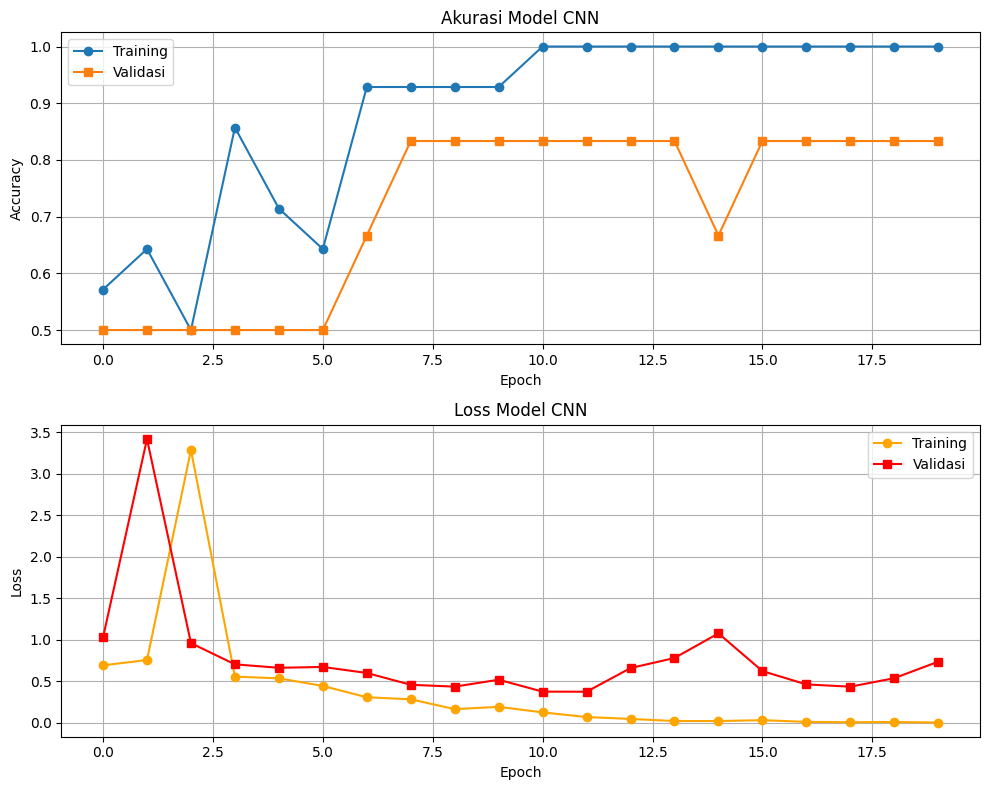

In [5]:
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=EPOCHS
)

# Grafik Accuracy dan Loss
plt.figure(figsize=(10, 8))
plt.subplot(2, 1, 1)
plt.plot(history.history["accuracy"], label="Training", marker='o')
plt.plot(history.history["val_accuracy"], label="Validasi", marker='s')
plt.title("Akurasi Model CNN")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(history.history["loss"], label="Training", marker='o', color='orange')
plt.plot(history.history["val_loss"], label="Validasi", marker='s', color='red')
plt.title("Loss Model CNN")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Langkah 5: Evaluasi Model, Confusion Matrix, dan Classification Report
Melakukan pengujian pada data validasi secara komprehensif untuk mengukur Precision, Recall, dan F1-Score serta menyimpan model berformat `.keras`.

In [6]:
loss, accuracy = model.evaluate(validation_data)
print("====================================")
print("HASIL VALIDASI")
print("====================================")
print("Validation Loss     :", round(loss, 4))
print("Validation Accuracy :", round(accuracy * 100, 2), "%")

validation_data.reset()
hasil = model.predict(validation_data)
y_pred = (hasil >= 0.5).astype(int).reshape(-1)
y_true = validation_data.classes

cm = confusion_matrix(y_true, y_pred)
print("\n====================================")
print("CONFUSION MATRIX")
print("====================================")
print(cm)

nama_kelas = list(validation_data.class_indices.keys())
print("\n====================================")
print("CLASSIFICATION REPORT")
print("====================================")
print(classification_report(y_true, y_pred, target_names=nama_kelas))

model.save("model_motor_mobil.keras")
print("[INFO] Model berhasil disimpan ke 'model_motor_mobil.keras'")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.8333 - loss: 0.7346

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8333 - loss: 0.7346


HASIL VALIDASI
Validation Loss     : 0.7346
Validation Accuracy : 83.33 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step



CONFUSION MATRIX
[[3 0]
 [1 2]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Mobil       0.75      1.00      0.86         3
       Motor       1.00      0.67      0.80         3

    accuracy                           0.83         6
   macro avg       0.88      0.83      0.83         6
weighted avg       0.88      0.83      0.83         6



[INFO] Model berhasil disimpan ke 'model_motor_mobil.keras'


### Bagian 1: Pelatihan Model (Train Module)
Membaca dataset citra mobil dan motor, melatih arsitektur CNN 2 blok konvolusi ber-padding same, dan menyimpan model.

In [2]:
import tensorflow as tf
import numpy as np
import random
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

dataset_dir = "Dataset 2/Dataset" if os.path.exists("Dataset 2/Dataset") else "Dataset"

datagen = ImageDataGenerator(rescale=1./255)
train_data = datagen.flow_from_directory(
    dataset_dir,
    target_size=(224, 224),
    batch_size=2,
    class_mode="binary",
    shuffle=True,
    seed=42
)

print("Jumlah data :", train_data.samples)
print("Kelas       :", train_data.class_indices)

model = Sequential([
    Input(shape=(224, 224, 3)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.fit(train_data, epochs=12)
model.save("model_motor_mobil.keras")
print("[INFO] Model berhasil disimpan ke model_motor_mobil.keras")

Found 20 images belonging to 2 classes.


Jumlah data : 20
Kelas       : {'Mobil': 0, 'Motor': 1}


Epoch 1/12


 1/10 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.5000 - loss: 0.6795

 2/10 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.7500 - loss: 0.3400

 3/10 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.5000 - loss: 6.3448

... (137 outputs left out)

 9/10 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 1.0000 - loss: 9.4251e-05

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 1.0000 - loss: 8.5014e-05

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - accuracy: 1.0000 - loss: 8.5014e-05


[INFO] Model berhasil disimpan ke model_motor_mobil.keras


### Bagian 2: Pengujian Model Citra Baru (Inference Module)
Memuat model dari disk dan menguji dua citra uji:
- `tes1.jpeg` (Citra Mobil) -> Target output: < 0.5 (MOBIL)
- `tes2.jpeg` (Citra Motor) -> Target output: >= 0.5 (MOTOR)

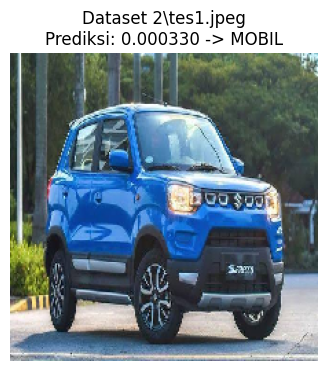

File: Dataset 2\tes1.jpeg
Nilai prediksi : 0.00033038356923498213
Hasil          : MOBIL



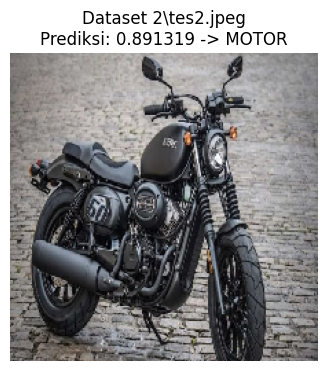

File: Dataset 2\tes2.jpeg
Nilai prediksi : 0.8913190960884094
Hasil          : MOTOR



In [3]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

loaded_model = load_model("model_motor_mobil.keras")

def uji_gambar(nama_file):
    if not os.path.exists(nama_file):
        alt_path = os.path.join("Dataset 2", nama_file)
        if os.path.exists(alt_path):
            nama_file = alt_path
    
    img_pil = image.load_img(nama_file, target_size=(224, 224))
    img_arr = image.img_to_array(img_pil) / 255.0
    img_input = np.expand_dims(img_arr, axis=0)

    hasil = loaded_model.predict(img_input, verbose=0)
    nilai = float(hasil[0][0])
    label = "MOTOR" if nilai >= 0.5 else "MOBIL"

    plt.figure(figsize=(4, 4))
    plt.imshow(img_pil)
    plt.title(f"{nama_file}\nPrediksi: {nilai:.6f} -> {label}")
    plt.axis('off')
    plt.show()

    print(f"File: {nama_file}")
    print(f"Nilai prediksi : {nilai}")
    print(f"Hasil          : {label}\n")

uji_gambar("tes1.jpeg")
uji_gambar("tes2.jpeg")

### Bagian 1: Pelatihan Model CNN 5 Kelas
Membaca dataset citra 5 kelas makanan (Bakwan Sayur, Bubur Tinotuan, Nasi Beras Merah, Plencing Kangkung, Wortel), melatih model, dan menyimpannya ke `model_makanan.keras`.

In [2]:
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

dataset_makanan = "Dataset 3/Dataset" if os.path.exists("Dataset 3/Dataset") else "Dataset"

datagen = ImageDataGenerator(rescale=1./255)
train_data = datagen.flow_from_directory(
    dataset_makanan,
    target_size=(224, 224),
    batch_size=2,
    class_mode="categorical"
)

print("Jumlah data :", train_data.samples)
print("Kelas       :", train_data.class_indices)

model = Sequential([
    Input(shape=(224, 224, 3)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(train_data, epochs=10)
model.save("model_makanan.keras")
print("[INFO] Model berhasil disimpan ke 'model_makanan.keras'")

Found 100 images belonging to 5 classes.


Jumlah data : 100
Kelas       : {'Bakwan Sayur': 0, 'Bubur Tinotuan': 1, 'Nasi Beras Merah': 2, 'Plencing Kangkung': 3, 'Wortel': 4}
Epoch 1/10


 1/50 ━━━━━━━━━━━━━━━━━━━━ 44s 915ms/step - accuracy: 0.0000e+00 - loss: 1.6618

 2/50 ━━━━━━━━━━━━━━━━━━━━ 7s 153ms/step - accuracy: 0.2500 - loss: 16.7740    

 3/50 ━━━━━━━━━━━━━━━━━━━━ 6s 132ms/step - accuracy: 0.1667 - loss: 17.4356

 4/50 ━━━━━━━━━━━━━━━━━━━━ 5s 124ms/step - accuracy: 0.1250 - loss: 13.7167

... (512 outputs left out)

49/50 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 1.0000 - loss: 1.3099e-04

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 1.0000 - loss: 1.2837e-04

50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 111ms/step - accuracy: 1.0000 - loss: 1.2837e-04


[INFO] Model berhasil disimpan ke 'model_makanan.keras'


### Bagian 2: Pengujian Citra Uji (tes0.jpeg s/d tes4.jpeg)
Menguji ke-5 citra uji satu per satu untuk mengevaluasi prediksi kelas dan probabilitas keyakinan model.

--- Uji Dataset 3\tes0.jpeg ---
Nilai probabilitas : 0.9999977350234985
Index kelas        : 0
Kelas terprediksi  : Bakwan Sayur

--- Uji Dataset 3\tes1.jpeg ---
Nilai probabilitas : 0.5094309449195862
Index kelas        : 4
Kelas terprediksi  : Wortel

--- Uji Dataset 3\tes2.jpeg ---
Nilai probabilitas : 0.8867880702018738
Index kelas        : 2
Kelas terprediksi  : Nasi Beras Merah

--- Uji Dataset 3\tes3.jpeg ---
Nilai probabilitas : 0.9928455948829651
Index kelas        : 3
Kelas terprediksi  : Plencing Kangkung



--- Uji Dataset 3\tes4.jpeg ---
Nilai probabilitas : 1.0
Index kelas        : 4
Kelas terprediksi  : Wortel



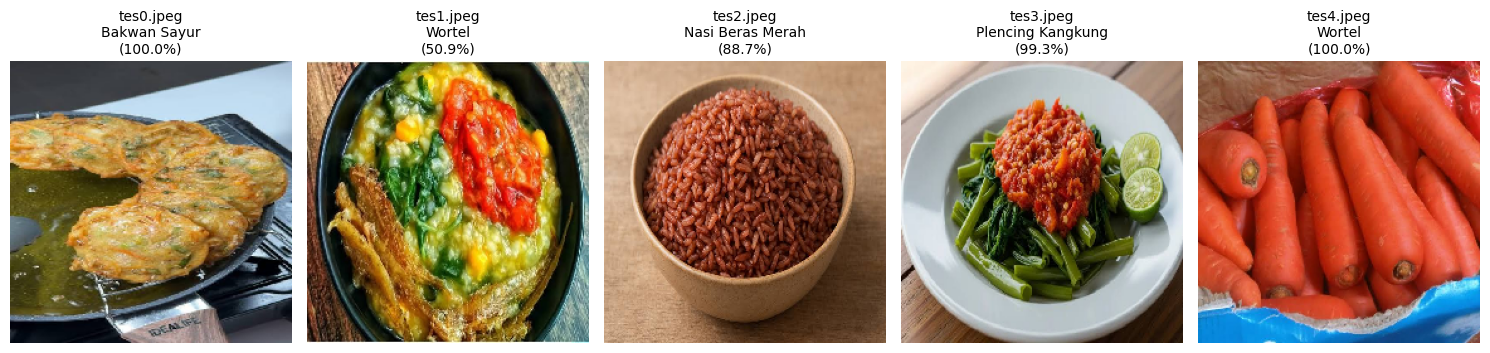

In [3]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

loaded_model = load_model("model_makanan.keras")

kelas = {
    0: "Bakwan Sayur",
    1: "Bubur Tinotuan",
    2: "Nasi Beras Merah",
    3: "Plencing Kangkung",
    4: "Wortel"
}

plt.figure(figsize=(15, 6))
for i in range(5):
    fname = f"tes{i}.jpeg"
    if not os.path.exists(fname):
        alt = os.path.join("Dataset 3", fname)
        if os.path.exists(alt):
            fname = alt

    img_pil = image.load_img(fname, target_size=(224, 224))
    img_arr = image.img_to_array(img_pil) / 255.0
    img_batch = np.expand_dims(img_arr, axis=0)

    hasil = loaded_model.predict(img_batch, verbose=0)
    index = int(np.argmax(hasil[0]))
    nilai = float(hasil[0][index])

    plt.subplot(1, 5, i+1)
    plt.imshow(img_pil)
    plt.title(f"tes{i}.jpeg\n{kelas[index]}\n({nilai*100:.1f}%)", fontsize=10)
    plt.axis('off')

    print(f"--- Uji {fname} ---")
    print("Nilai probabilitas :", nilai)
    print("Index kelas        :", index)
    print("Kelas terprediksi  :", kelas[index])
    print()

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator

dataset_dir = "Latihan/Dataset" if os.path.exists("Latihan/Dataset") else "Dataset"

datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    dataset_dir,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    subset="training",
    shuffle=True
)

val_data = datagen.flow_from_directory(
    dataset_dir,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

num_classes = len(train_data.class_indices)
print("Kelas terdaftar:", train_data.class_indices)

model = Sequential([
    Input(shape=(224, 224, 3)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
history = model.fit(train_data, validation_data=val_data, epochs=10)

In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

dataset_wajah = "Tugas/Dataset" if os.path.exists("Tugas/Dataset") else "Dataset"

datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    validation_split=0.25
)

train_data = datagen.flow_from_directory(
    dataset_wajah,
    target_size=(224, 224),
    batch_size=4,
    class_mode="categorical",
    subset="training"
)

val_data = datagen.flow_from_directory(
    dataset_wajah,
    target_size=(224, 224),
    batch_size=4,
    class_mode="categorical",
    subset="validation"
)

print("Daftar Anggota:", train_data.class_indices)

model = Sequential([
    Input(shape=(224, 224, 3)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(len(train_data.class_indices), activation="softmax")
])

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(train_data, validation_data=val_data, epochs=10)
model.save("model_wajah_login.keras")